In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import os
import json
import numpy as np
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import gpflow
import tensorflow as tf

2026-11-25 09:11:25.760853: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-25 09:11:25.781788: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1795623085.809883   37904 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1795623085.817190   37904 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-25 09:11:25.845455: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

In [2]:
from utils.hm_pyfunctions import *
utils_path = '../utils/'

In [3]:
# get config information
utils_dir = '../utils/'

with open(os.path.join(utils_dir, "param_info.json"), "r") as f:
    param_info = json.load(f)
u_params = param_info['u_params']
pft_params = param_info['pft_params']

with open(os.path.join(utils_dir, "biome_info.json"), "r") as f:
    biome_info = json.load(f)

### Biome emulators

In [4]:
### Load data
ds_params_lhc = xr.open_dataset('../clm-hm/paramsets/clm6lhc_01192025_v3.nc')
ds_lhc = xr.open_dataset('../data/ctsm53065_lhc_biome_1850-2023.nc')

In [5]:
### Load wave1 data
ds_params_wave1 = xr.open_dataset('../clm-hm/paramsets/ctsm53065_wave1_12032025.nc')
ds_wave1 = xr.open_dataset('../data/ctsm53065_wave1_biome_1850-2023.nc')

In [6]:
### Load wave2 data
ds_params_wave2 = xr.open_dataset('../clm-hm/paramsets/ctsm53065_wave2_12232025.nc')
ds_wave2 = xr.open_dataset('../data/ctsm53065_wave2_biome_1850-2023.nc')

In [7]:
### Load wave3 data
ds_params_wave3 = xr.open_dataset('../clm-hm/paramsets/ctsm53065_wave3_01012026.nc')
ds_wave3 = xr.open_dataset('../data/ctsm53065_wave3_biome_1850-2023.nc')

In [8]:
### Load wave4 data
ds_params_wave4 = xr.open_dataset('../clm-hm/paramsets/ctsm53065_wave4_02042026.nc')
ds_wave4 = xr.open_dataset('../data/ctsm53065_wave4_biome_1850-2023.nc')

In [9]:
# concat
ds_X = xr.concat([ds_params_lhc.lhc_params, ds_params_wave1.wave1_params, ds_params_wave2.wave2_params, ds_params_wave3.wave3_params, ds_params_wave4.wave4_params], dim="ens")
ds_X = ds_X.assign_coords(ens=range(0, len(ds_X.ens)))
ds_Y = xr.concat([ds_lhc.sel(ens=slice(1,201)),ds_wave1,ds_wave2,ds_wave3,ds_wave4],dim='ens') # drop default lhc0000

In [13]:
# train test split (same for all emulators)
np.random.seed(20)
ntest = 100
biome_pfts = biome_info['13']['pfts_in_biome']
X = build_biome_X(ds_X,u_params,pft_params,biome_pfts)
ix_test = np.random.choice(np.arange(len(X)), size=ntest, replace=False)
ix_train = np.where(~np.isin(np.arange(len(X)), ix_test))[0]

INFO:tensorflow:Assets written to: ./emulators/biome_lai_1/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lai_1/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lai_2/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lai_2/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lai_3/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lai_3/assets


... (16 outputs left out)

INFO:tensorflow:Assets written to: ./emulators/biome_lai_12/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lai_12/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lai_13/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lai_13/assets


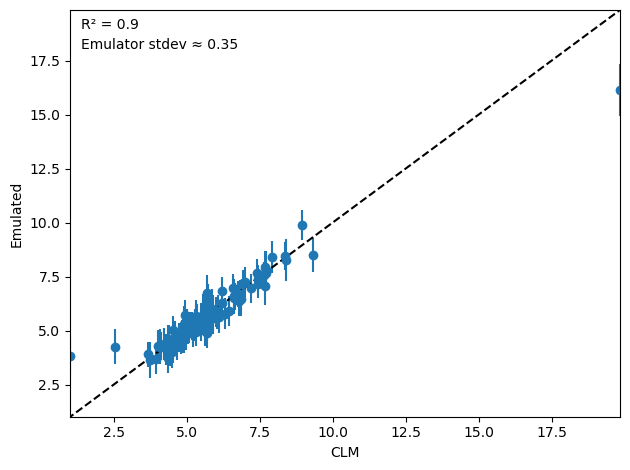

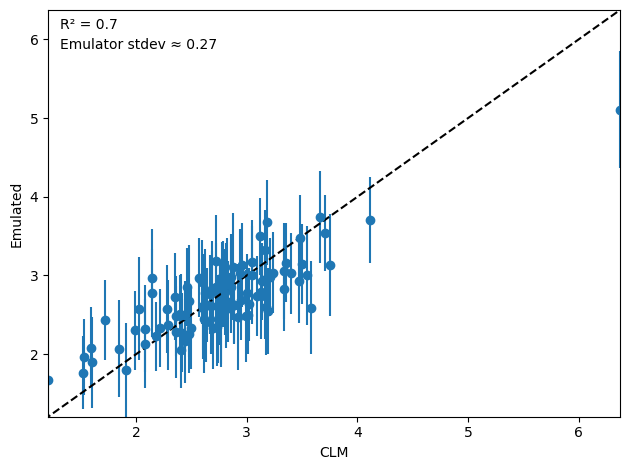

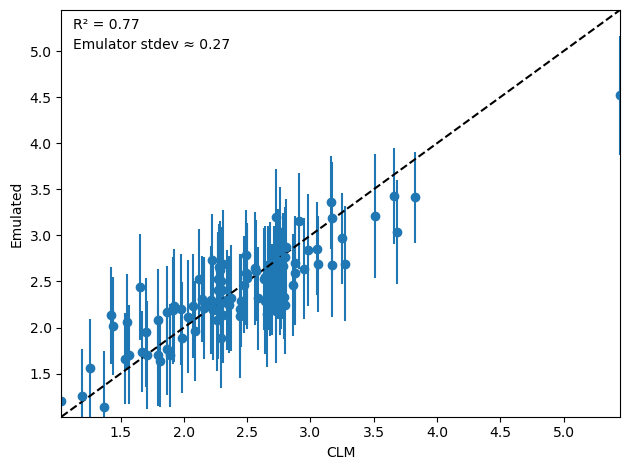

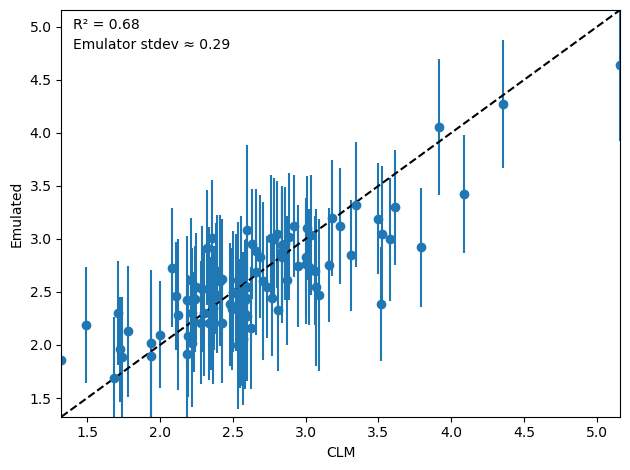

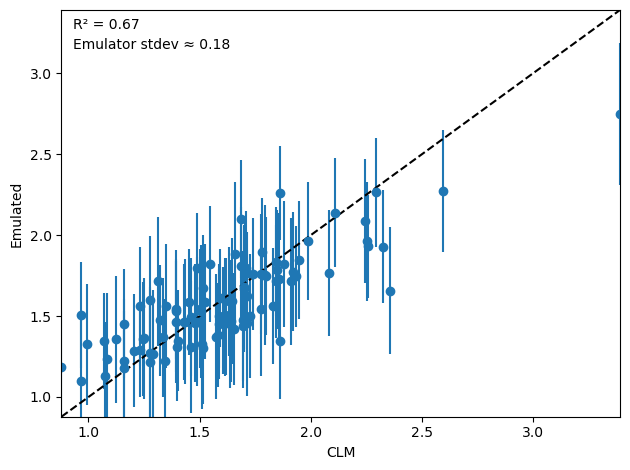

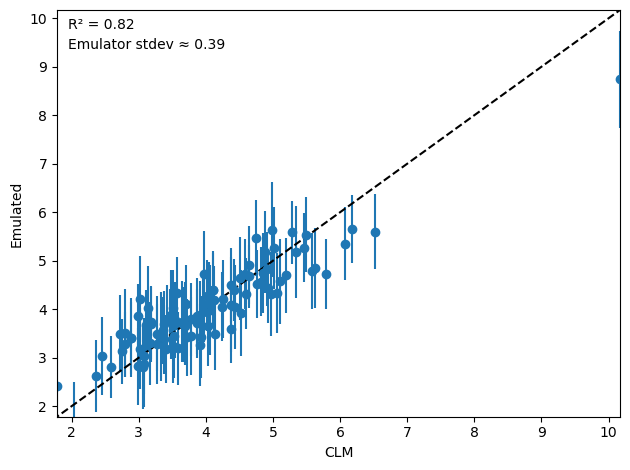

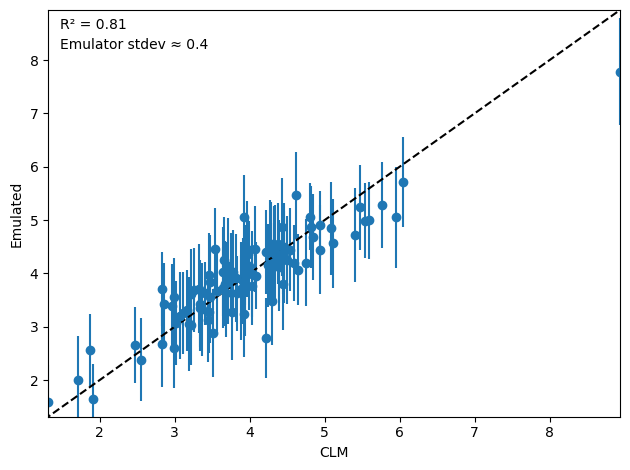

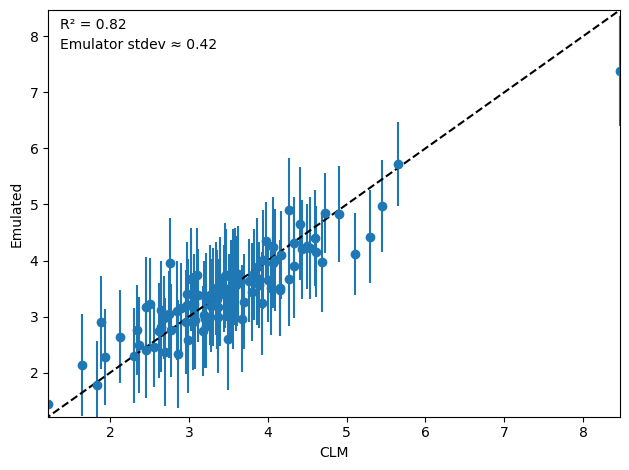

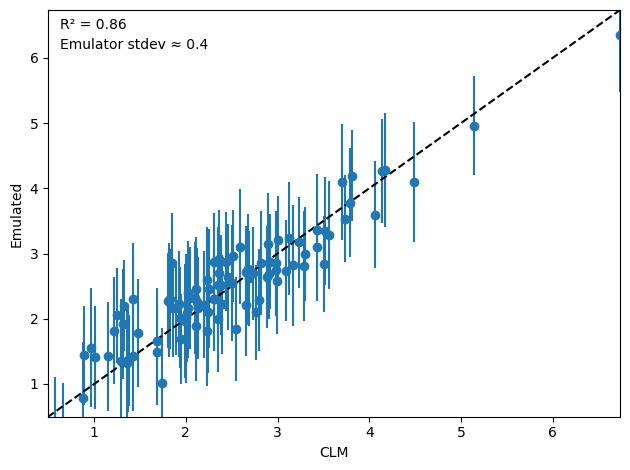

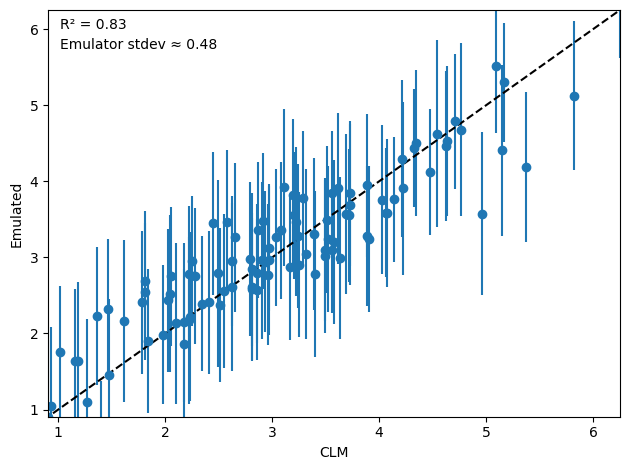

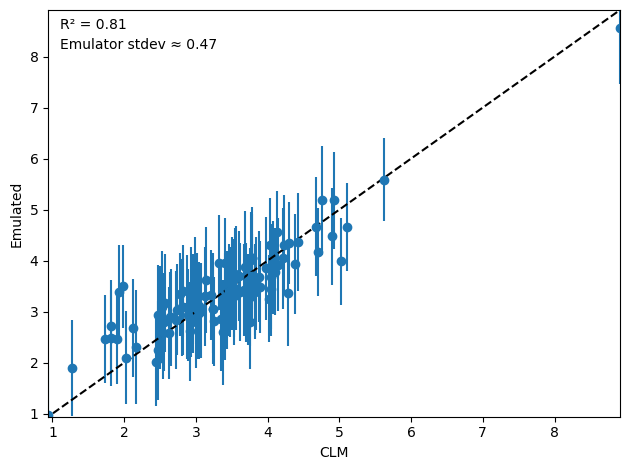

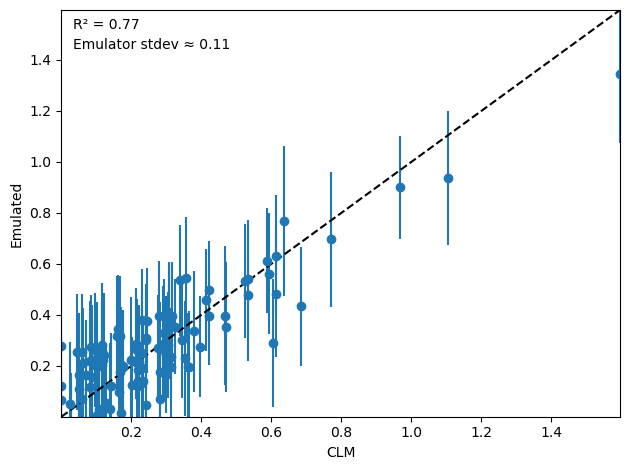

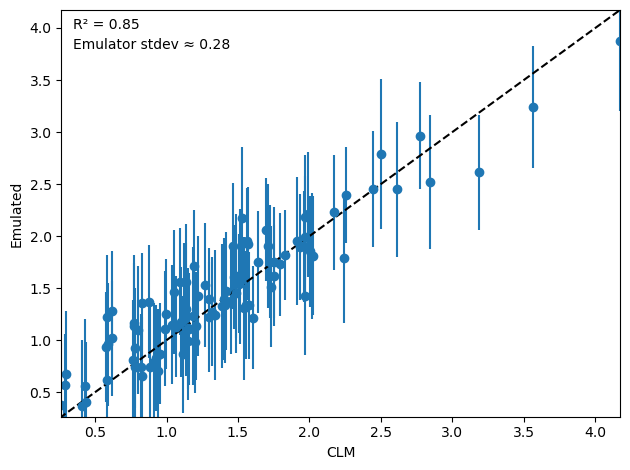

In [12]:
# Train LAI emulators (2001-2020)
start_year = '2001'
end_year = '2020'
y_data = ds_Y.TLAI_biome_amax.sel(year=slice(start_year,end_year)).mean(dim='year')

emulator_save_dir = './emulators/biome_lai_'
validation_fig_dir = './figs/emulator_validation_laimax_biome'

for b in range(1,14):
    
    biome_pfts = biome_info[str(b)]['pfts_in_biome']
    X = build_biome_X(ds_X,u_params,pft_params,biome_pfts)
    Y = y_data.sel(biome=b).values
    X_test, X_train = X[ix_test,:], X[ix_train,:]
    y_test, y_train = Y[ix_test].reshape(-1,1), Y[ix_train].reshape(-1,1)

    # build kernel
    num_params = np.shape(X)[1]
    kernel_dict = build_kernel_dict(num_params)
    best_kernel = select_kernel(kernel_dict,X_train,X_test,y_train,y_test)

    # Train 
    emulator = train_model(X_train, y_train, best_kernel)

    # Validate
    y_pred, sd, coef_deter = validate_model(emulator, X_test, y_test)

    # Save 
    savedir = str(emulator_save_dir+str(b))
    save_model(emulator, savedir, num_params)

    # Plot the validation
    outfile = validation_fig_dir+str(b)+'.png'
    plot_emulator_val(y_test, y_pred, sd, coef_deter, outfile)


INFO:tensorflow:Assets written to: ./emulators/biome_gpp_1/assets


INFO:tensorflow:Assets written to: ./emulators/biome_gpp_1/assets


INFO:tensorflow:Assets written to: ./emulators/biome_gpp_2/assets


INFO:tensorflow:Assets written to: ./emulators/biome_gpp_2/assets


INFO:tensorflow:Assets written to: ./emulators/biome_gpp_3/assets


INFO:tensorflow:Assets written to: ./emulators/biome_gpp_3/assets


... (16 outputs left out)

INFO:tensorflow:Assets written to: ./emulators/biome_gpp_12/assets


INFO:tensorflow:Assets written to: ./emulators/biome_gpp_12/assets


INFO:tensorflow:Assets written to: ./emulators/biome_gpp_13/assets


INFO:tensorflow:Assets written to: ./emulators/biome_gpp_13/assets


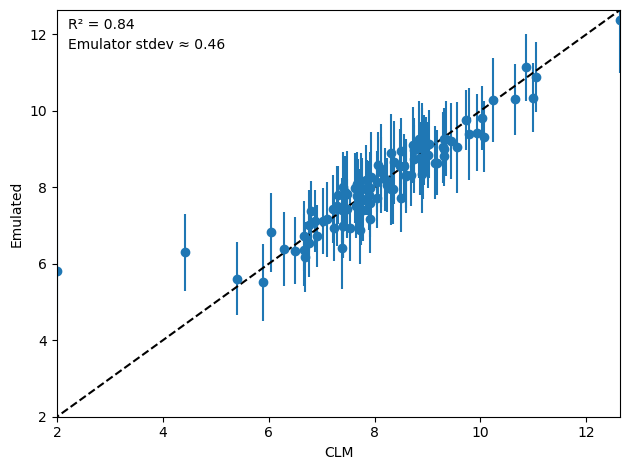

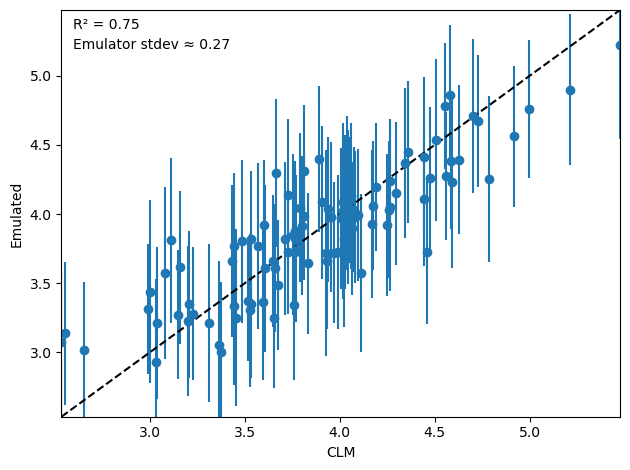

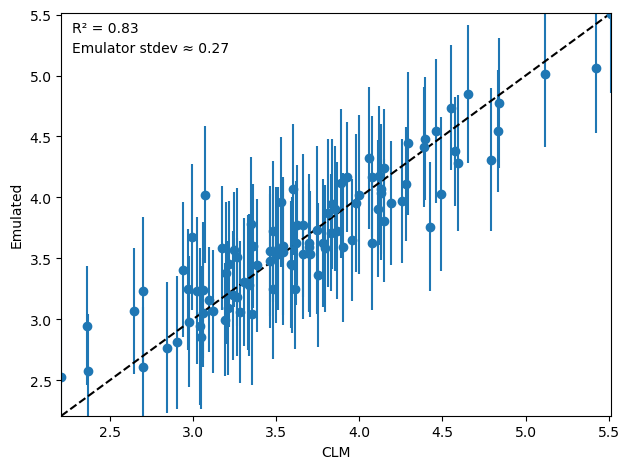

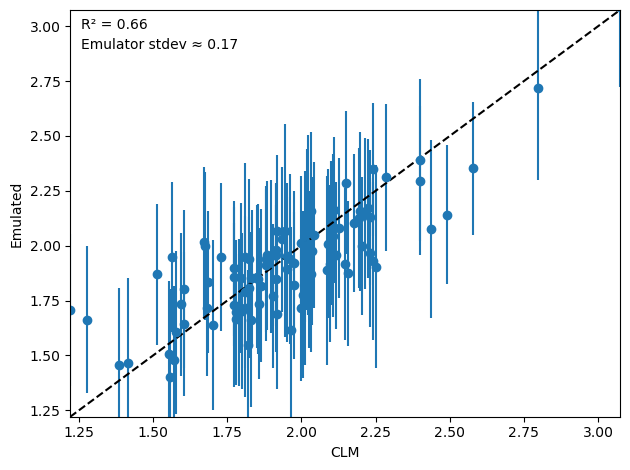

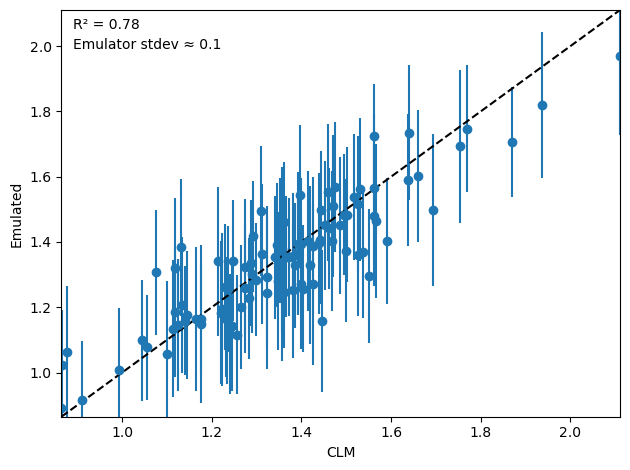

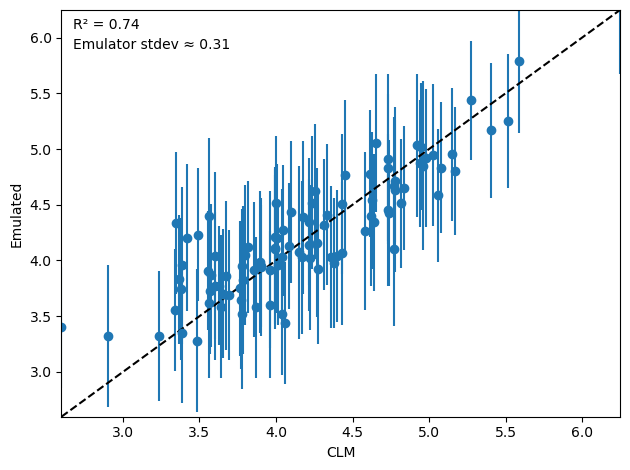

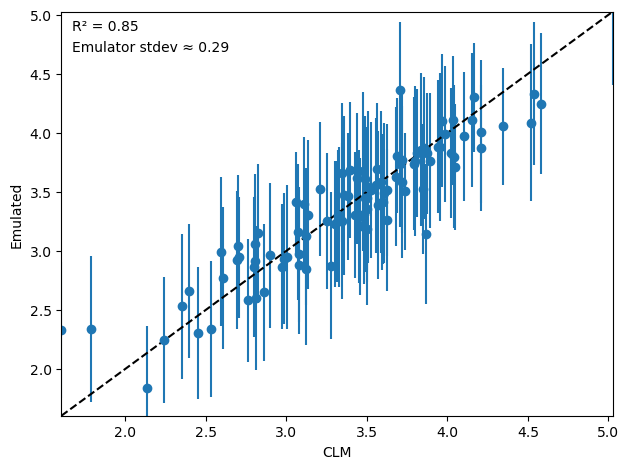

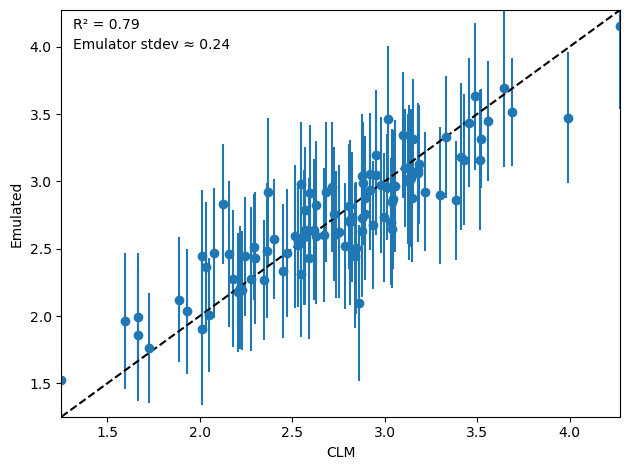

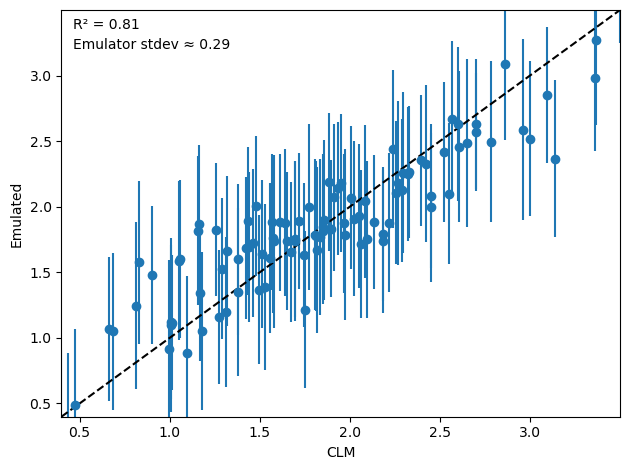

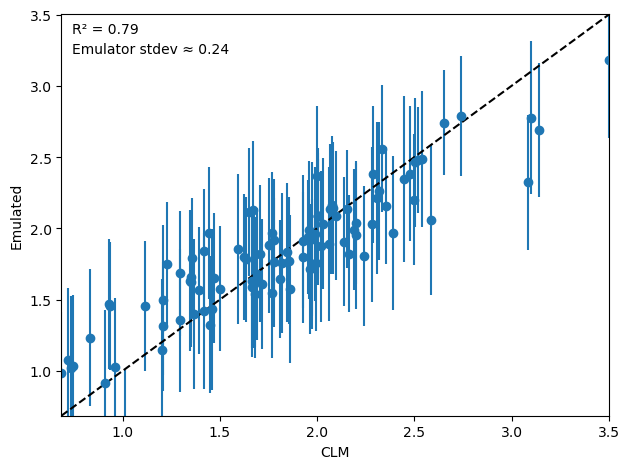

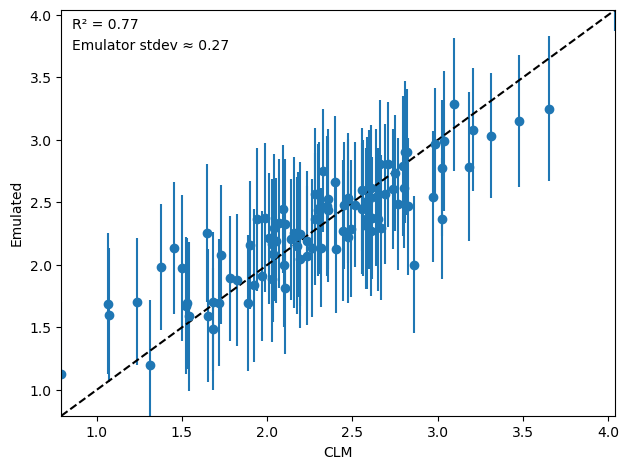

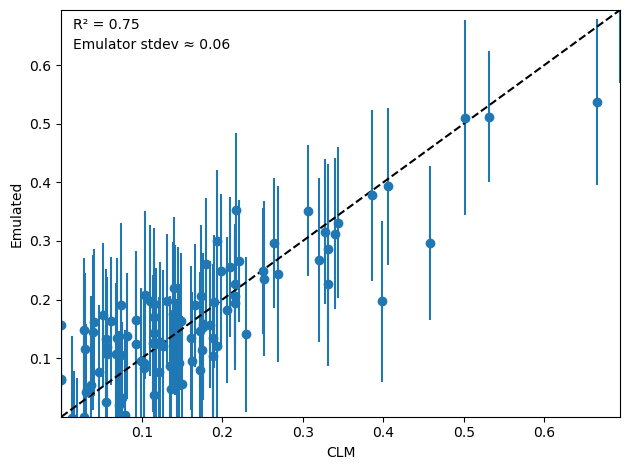

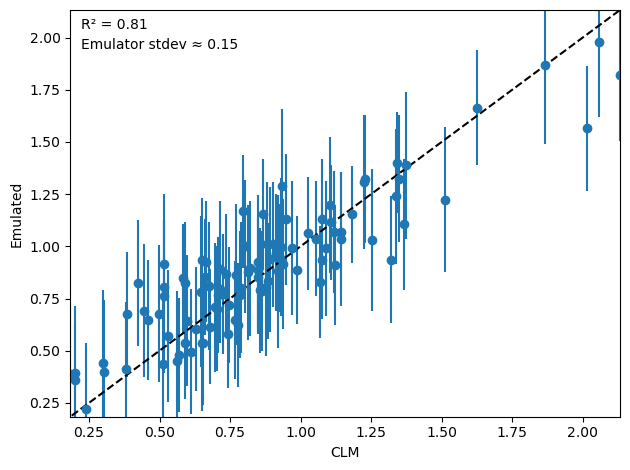

In [13]:
# Train GPP emulators # (2001,2017)
start_year = '2001'
end_year = '2017'

y_data = (60*60*24*ds_Y.GPP_biome_amean).sel(year=slice(start_year,end_year)).mean(dim='year')

emulator_save_dir = './emulators/biome_gpp_'
validation_fig_dir = './figs/emulator_validation_gpp_biome'

for b in range(1,14):
    
    biome_pfts = biome_info[str(b)]['pfts_in_biome']
    X = build_biome_X(ds_X,u_params,pft_params,biome_pfts)
    Y = y_data.sel(biome=b).values
    X_test, X_train = X[ix_test,:], X[ix_train,:]
    y_test, y_train = Y[ix_test].reshape(-1,1), Y[ix_train].reshape(-1,1)

    # build kernel
    num_params = np.shape(X)[1]
    kernel_dict = build_kernel_dict(num_params)
    best_kernel = select_kernel(kernel_dict,X_train,X_test,y_train,y_test)

    # Train 
    emulator = train_model(X_train, y_train, best_kernel)

    # Validate
    y_pred, sd, coef_deter = validate_model(emulator, X_test, y_test)

    # Save 
    savedir = str(emulator_save_dir+str(b))
    save_model(emulator, savedir, num_params)

    # Plot the validation
    outfile = validation_fig_dir+str(b)+'.png'
    plot_emulator_val(y_test, y_pred, sd, coef_deter, outfile)


INFO:tensorflow:Assets written to: ./emulators/biome_tvc_1/assets


INFO:tensorflow:Assets written to: ./emulators/biome_tvc_1/assets


INFO:tensorflow:Assets written to: ./emulators/biome_tvc_2/assets


INFO:tensorflow:Assets written to: ./emulators/biome_tvc_2/assets


INFO:tensorflow:Assets written to: ./emulators/biome_tvc_3/assets


INFO:tensorflow:Assets written to: ./emulators/biome_tvc_3/assets


... (16 outputs left out)

INFO:tensorflow:Assets written to: ./emulators/biome_tvc_12/assets


INFO:tensorflow:Assets written to: ./emulators/biome_tvc_12/assets


INFO:tensorflow:Assets written to: ./emulators/biome_tvc_13/assets


INFO:tensorflow:Assets written to: ./emulators/biome_tvc_13/assets


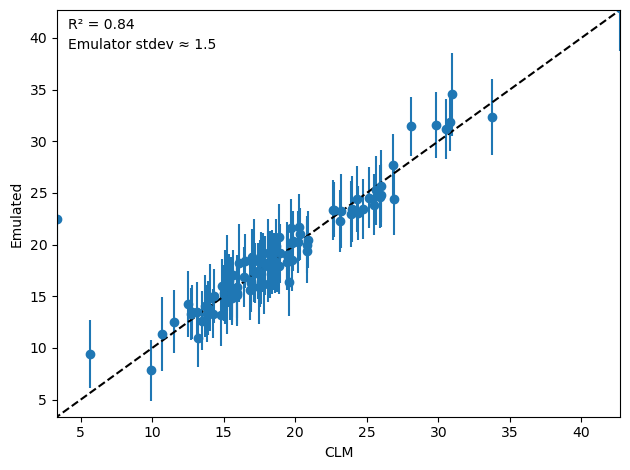

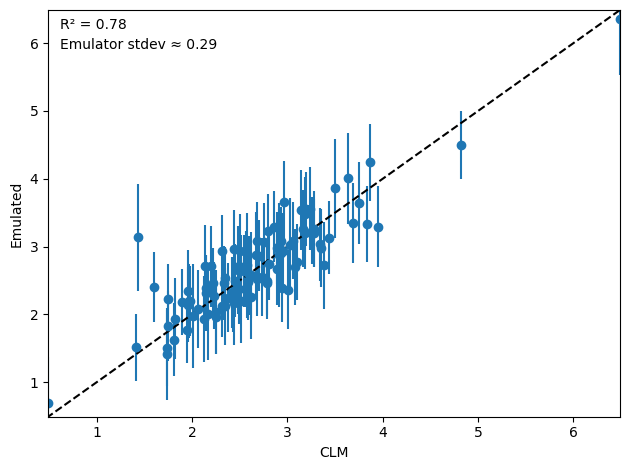

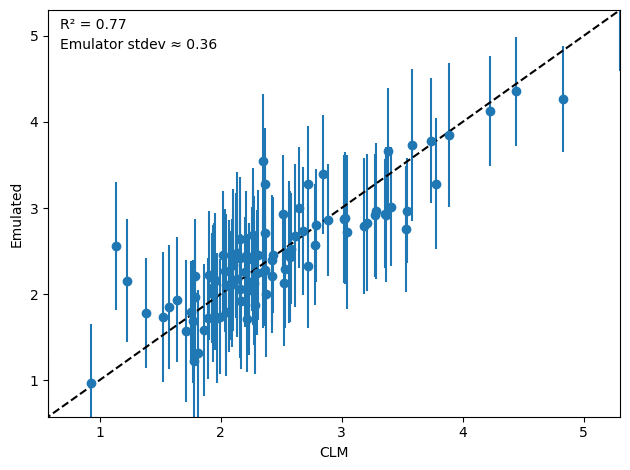

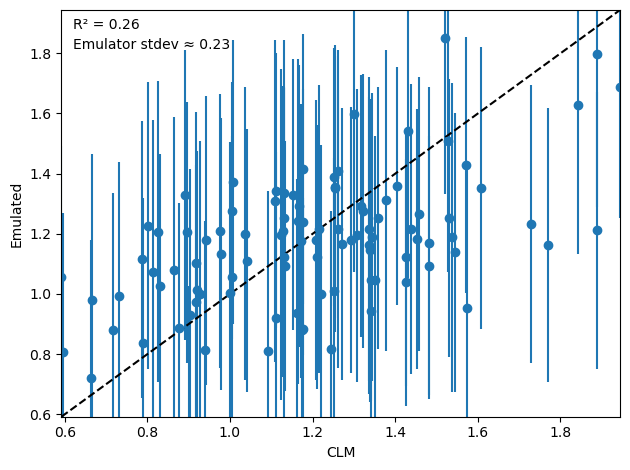

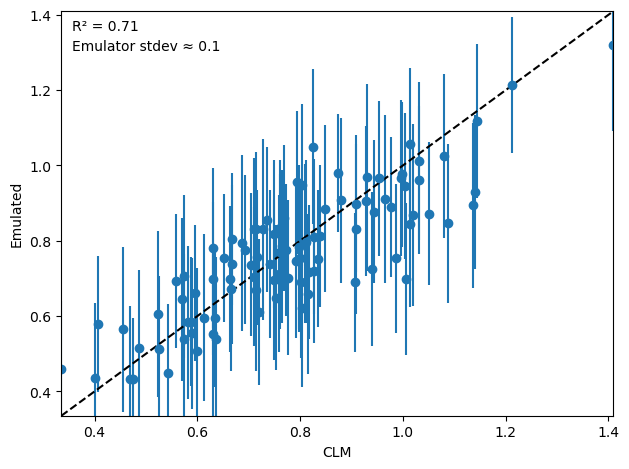

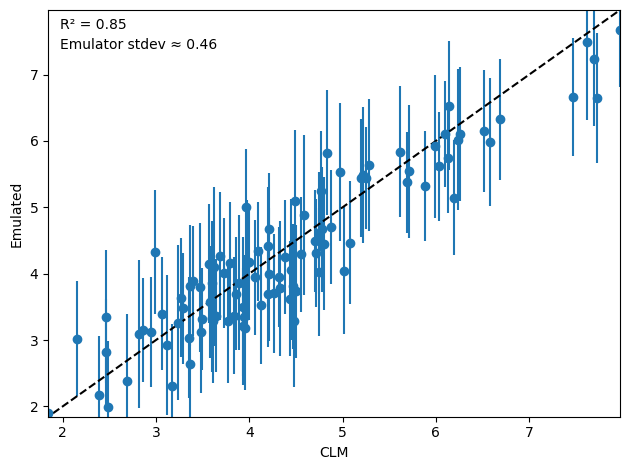

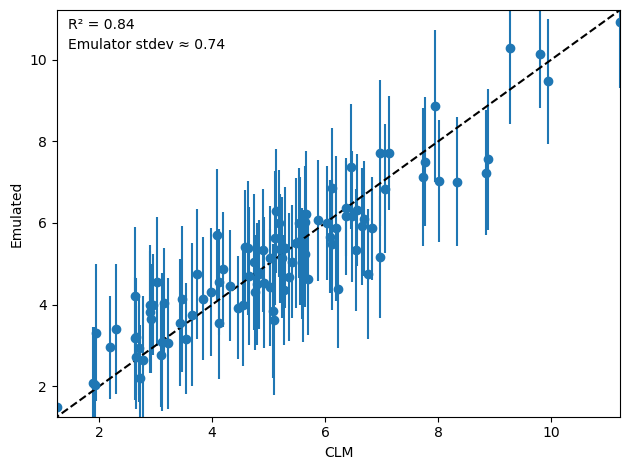

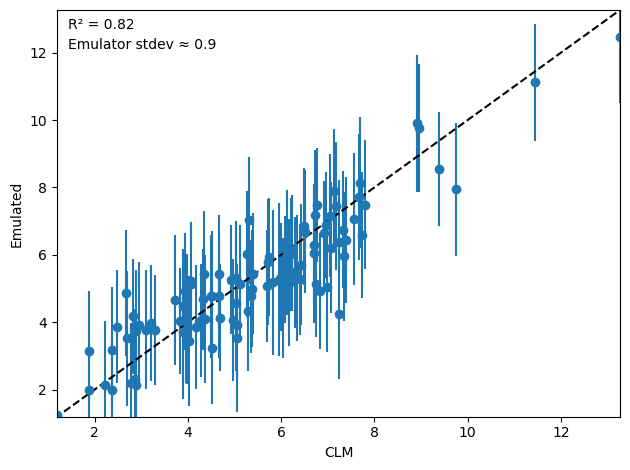

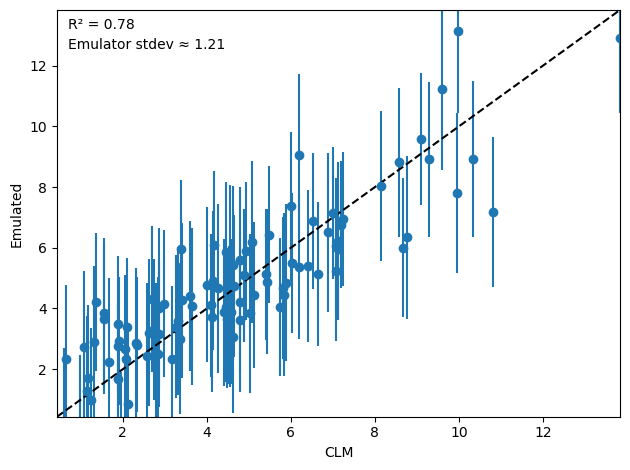

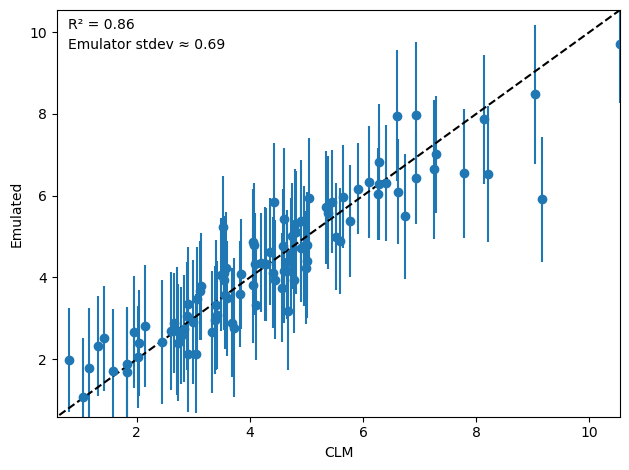

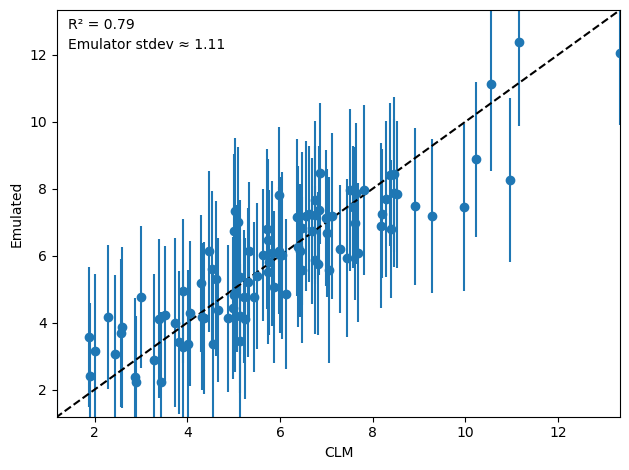

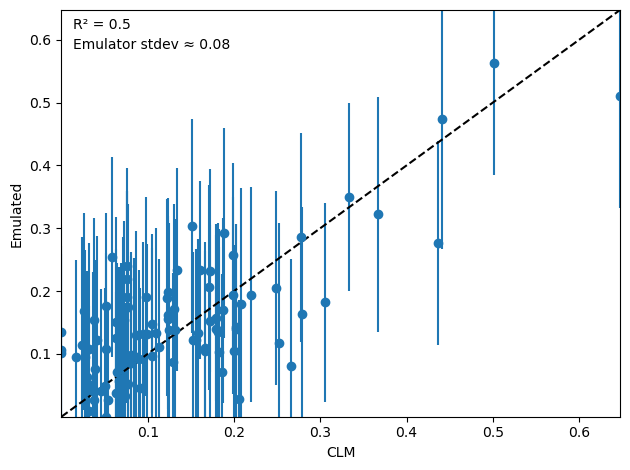

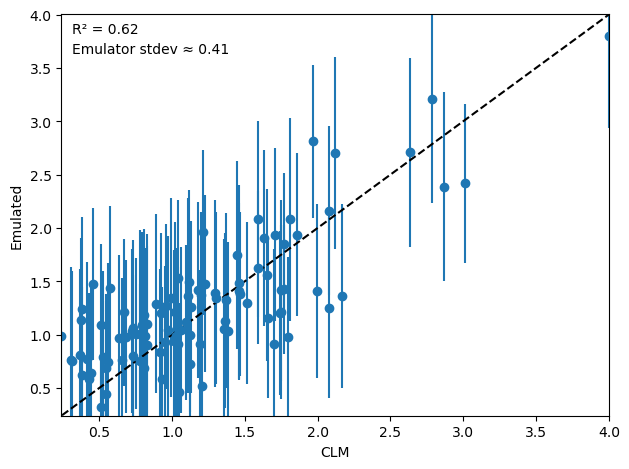

In [14]:
# Train tvc emulators # (2000,2019)
start_year = '2000'
end_year = '2019'
y_data = ((1/1000)*ds_Y.TOTVEGC_biome_amean).sel(year=slice(start_year,end_year)).mean(dim='year')

emulator_save_dir = './emulators/biome_tvc_'
validation_fig_dir = './figs/emulator_validation_tvc_biome'

for b in range(1,14):
    
    biome_pfts = biome_info[str(b)]['pfts_in_biome']
    X = build_biome_X(ds_X,u_params,pft_params,biome_pfts)
    Y = y_data.sel(biome=b).values
    X_test, X_train = X[ix_test,:], X[ix_train,:]
    y_test, y_train = Y[ix_test].reshape(-1,1), Y[ix_train].reshape(-1,1)

    # build kernel
    num_params = np.shape(X)[1]
    kernel_dict = build_kernel_dict(num_params)
    best_kernel = select_kernel(kernel_dict,X_train,X_test,y_train,y_test)
    
    # Train 
    emulator = train_model(X_train, y_train, best_kernel)

    # Validate
    y_pred, sd, coef_deter = validate_model(emulator, X_test, y_test)

    # Save 
    savedir = str(emulator_save_dir+str(b))
    save_model(emulator, savedir, num_params)

    # Plot the validation
    outfile = validation_fig_dir+str(b)+'.png'
    plot_emulator_val(y_test, y_pred, sd, coef_deter, outfile)


INFO:tensorflow:Assets written to: ./emulators/biome_lh_1/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lh_1/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lh_2/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lh_2/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lh_3/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lh_3/assets


... (16 outputs left out)

INFO:tensorflow:Assets written to: ./emulators/biome_lh_12/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lh_12/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lh_13/assets


INFO:tensorflow:Assets written to: ./emulators/biome_lh_13/assets


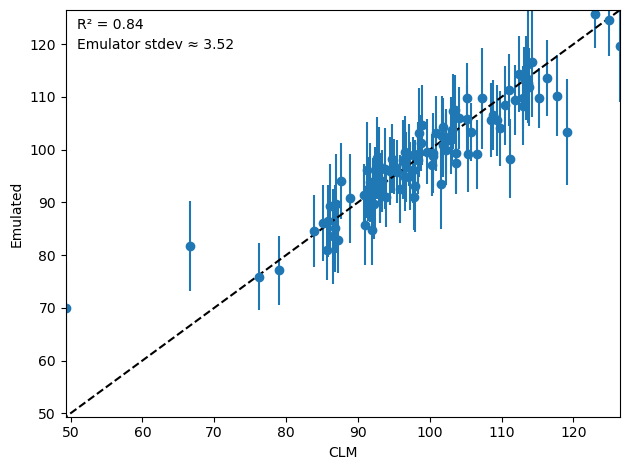

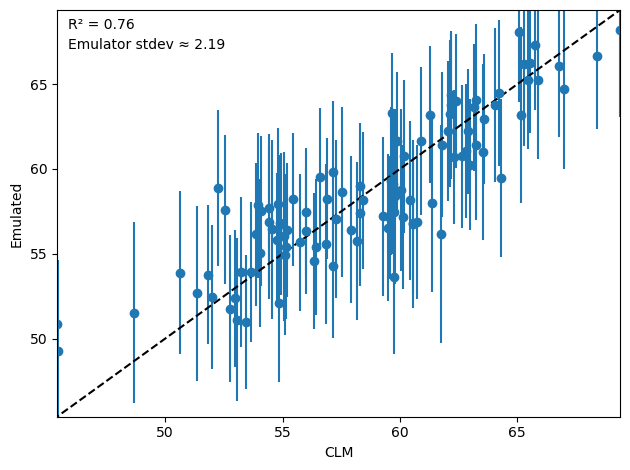

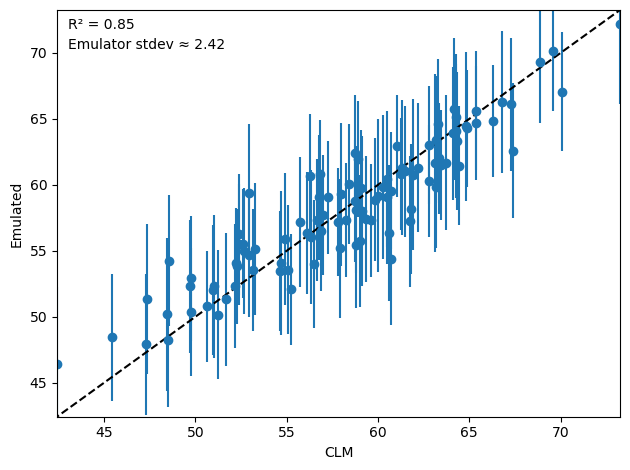

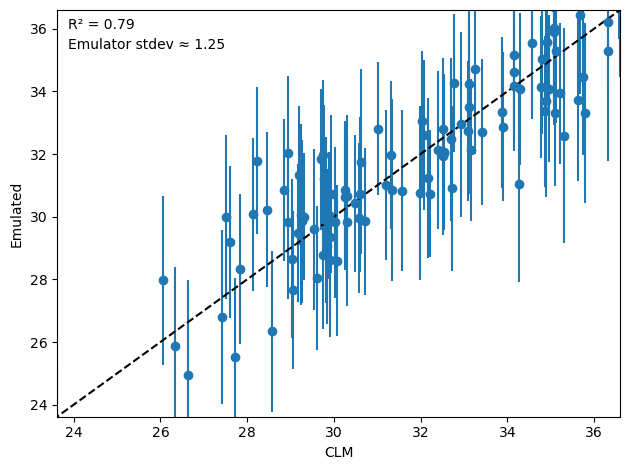

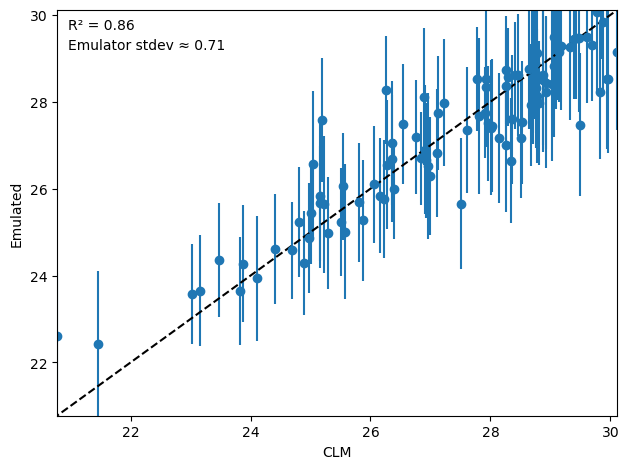

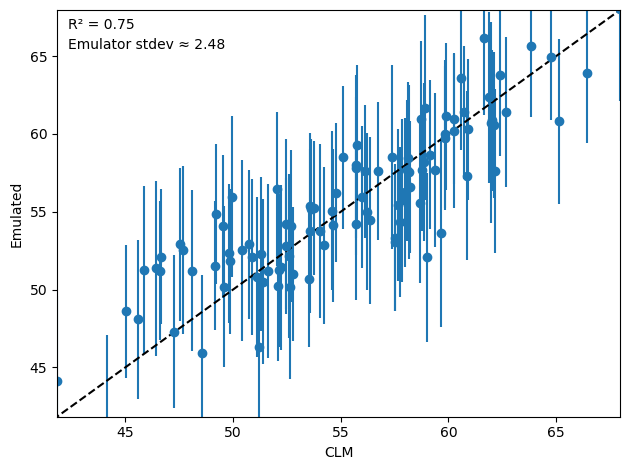

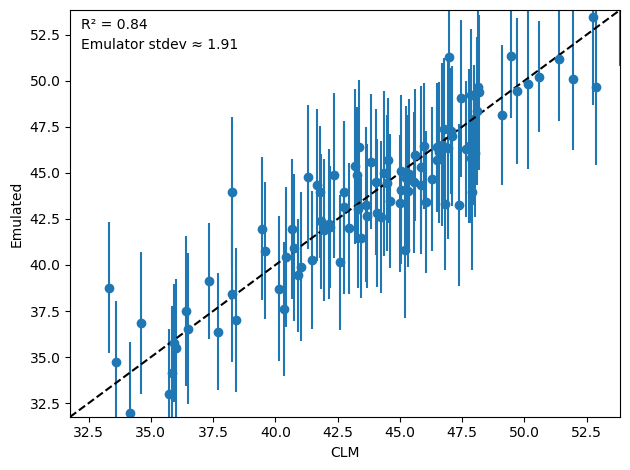

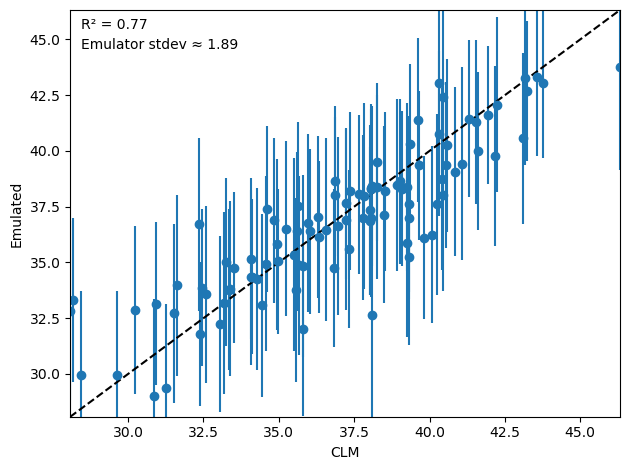

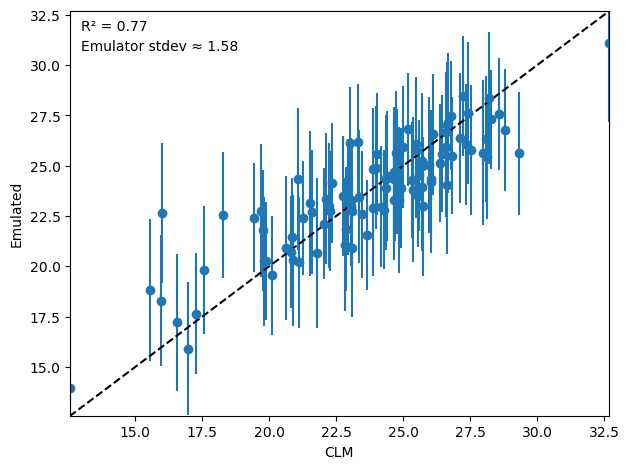

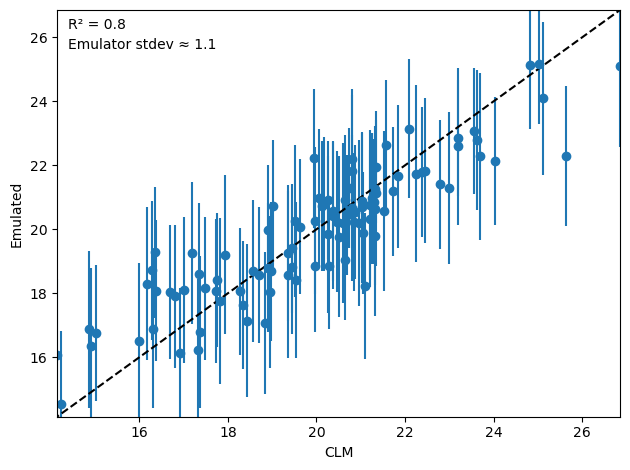

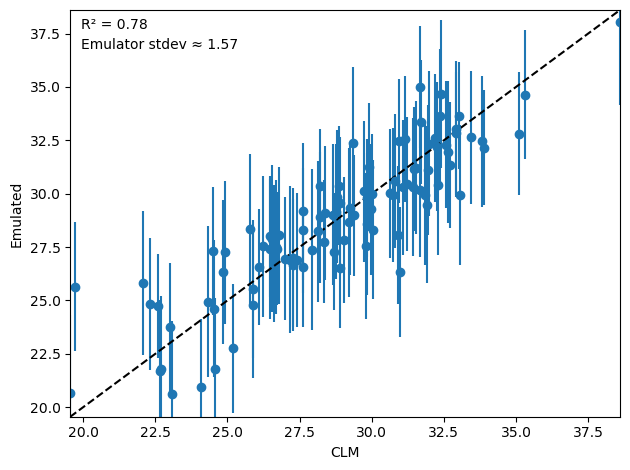

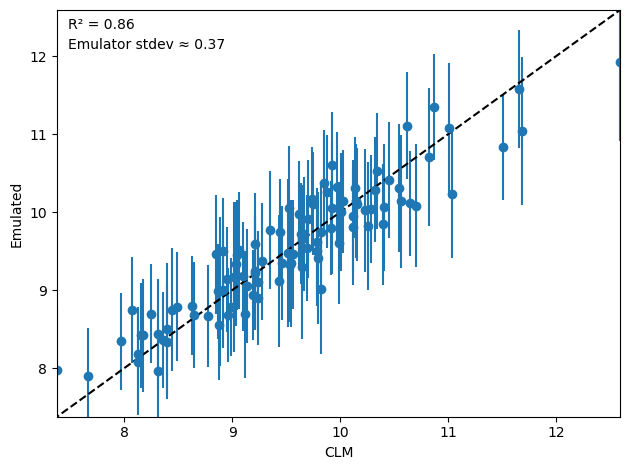

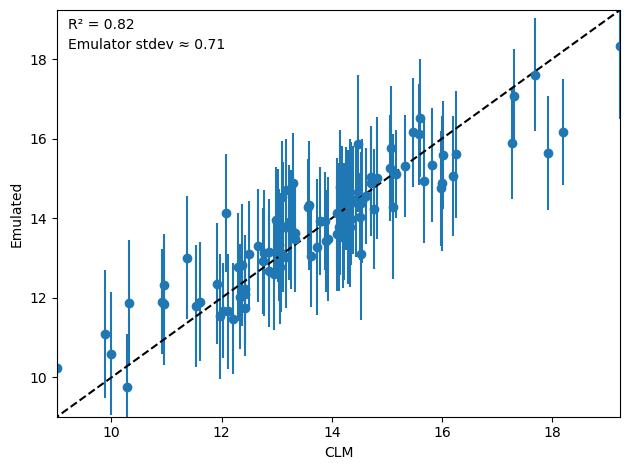

In [15]:
# Train ET emulators
start_year = '2000'
end_year = '2014'
y_data = ds_Y.EFLX_LH_TOT_biome_amean.sel(year=slice(start_year,end_year)).mean(dim='year')

emulator_save_dir = './emulators/biome_lh_'
validation_fig_dir = './figs/emulator_validation_lh_biome'

for b in range(1,14):
    
    biome_pfts = biome_info[str(b)]['pfts_in_biome']
    X = build_biome_X(ds_X,u_params,pft_params,biome_pfts)
    Y = y_data.sel(biome=b).values
    X_test, X_train = X[ix_test,:], X[ix_train,:]
    y_test, y_train = Y[ix_test].reshape(-1,1), Y[ix_train].reshape(-1,1)

    # build kernel
    num_params = np.shape(X)[1]
    kernel_dict = build_kernel_dict(num_params)
    best_kernel = select_kernel(kernel_dict,X_train,X_test,y_train,y_test)

    # Train 
    emulator = train_model(X_train, y_train, best_kernel)

    # Validate
    y_pred, sd, coef_deter = validate_model(emulator, X_test, y_test)

    # Save 
    savedir = str(emulator_save_dir+str(b))
    save_model(emulator, savedir, num_params)

    # Plot the validation
    outfile = validation_fig_dir+str(b)+'.png'
    plot_emulator_val(y_test, y_pred, sd, coef_deter, outfile)


### Evaluation plot

In [14]:
# LAI
r2_lai_eval = np.empty((1,13))
var_lai_eval= np.empty((1,13))

start_year = '2001'
end_year = '2020'
y_data = ds_Y.TLAI_biome_amax.sel(year=slice(start_year,end_year)).mean(dim='year')

emulator_dir = './emulators/biome_lai_'
for b in range(1,14):
    biome_pfts = biome_info[str(b)]['pfts_in_biome']
    X = build_biome_X(ds_X,u_params,pft_params,biome_pfts)
    Y = y_data.sel(biome=b).values
    X_test = X[ix_test,:]
    y_test = Y[ix_test]#.reshape(-1,1)

    loaded_emulator = tf.saved_model.load(emulator_dir + str(b))
    y_pred, y_pred_var = loaded_emulator.compiled_predict_f(X_test)
    r2 = np.corrcoef(y_pred.numpy().flatten(),y_test)
    r2_lai_eval[0,b-1] = round(r2[0,1],3)
    var_lai_eval[0,b-1]= np.median(y_pred_var)


2026-11-25 09:16:52.712044: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


In [16]:
# GPP
r2_gpp_eval = np.empty((1,13))
var_gpp_eval= np.empty((1,13))

start_year = '2001'
end_year = '2017'
y_data = ds_Y.GPP_biome_amean.sel(year=slice(start_year,end_year)).mean(dim='year')

for w in range(1,5):
    emulator_dir = './emulators/biome_gpp_'
    for b in range(1,14):
        biome_pfts = biome_info[str(b)]['pfts_in_biome']
        X = build_biome_X(ds_X,u_params,pft_params,biome_pfts)
        Y = y_data.sel(biome=b).values
        X_test = X[ix_test,:]
        y_test = Y[ix_test]#.reshape(-1,1)
    
        loaded_emulator = tf.saved_model.load(emulator_dir + str(b))
        y_pred, y_pred_var = loaded_emulator.compiled_predict_f(X_test)
        r2 = np.corrcoef(y_pred.numpy().flatten(),y_test)
        r2_gpp_eval[0,b-1] = round(r2[0,1],3)
        var_gpp_eval[0,b-1]= np.median(y_pred_var)

In [17]:
# TVC
r2_tvc_eval = np.empty((1,13))
var_tvc_eval = np.empty((1,13))

start_year = '2000'
end_year = '2019'
y_data = ds_Y.TOTVEGC_biome_amean.sel(year=slice(start_year,end_year)).mean(dim='year')

emulator_dir = './emulators/biome_tvc_'
for b in range(1,14):
    biome_pfts = biome_info[str(b)]['pfts_in_biome']
    X = build_biome_X(ds_X,u_params,pft_params,biome_pfts)
    Y = y_data.sel(biome=b).values
    X_test = X[ix_test,:]
    y_test = Y[ix_test]#.reshape(-1,1)

    loaded_emulator = tf.saved_model.load(emulator_dir + str(b))
    y_pred, y_pred_var = loaded_emulator.compiled_predict_f(X_test)
    r2 = np.corrcoef(y_pred.numpy().flatten(),y_test)
    r2_tvc_eval[0,b-1] = round(r2[0,1],3)
    var_tvc_eval[0,b-1] = np.mean(y_pred_var)

In [18]:
# Latent Heat
r2_lh_eval = np.empty((1,13))
var_lh_eval = np.empty((1,13))

start_year = '2000'
end_year = '2014'
y_data = ds_Y.EFLX_LH_TOT_biome_amean.sel(year=slice(start_year,end_year)).mean(dim='year')

emulator_dir = './emulators/biome_lh_'
for b in range(1,14):
    biome_pfts = biome_info[str(b)]['pfts_in_biome']
    X = build_biome_X(ds_X,u_params,pft_params,biome_pfts)
    Y = y_data.sel(biome=b).values
    X_test = X[ix_test,:]
    y_test = Y[ix_test]#.reshape(-1,1)

    loaded_emulator = tf.saved_model.load(emulator_dir + str(b))
    y_pred, y_pred_var = loaded_emulator.compiled_predict_f(X_test)
    r2 = np.corrcoef(y_pred.numpy().flatten(),y_test)
    r2_lh_eval[0,b-1] = round(r2[0,1],3)
    var_lh_eval[0,b-1] = np.median(y_pred_var)

In [19]:
r2_eval = np.empty((4,13))
r2_eval[0,:] = r2_lai_eval[0]
r2_eval[1,:] = r2_tvc_eval[0]
r2_eval[2,:] = r2_gpp_eval[0]
r2_eval[3,:] = r2_lh_eval[0]

In [20]:
from matplotlib.colors import ListedColormap, BoundaryNorm

N = 13

biome_colors = [
    "#004D19","#5D9945","darkseagreen",  # (tropic, tropic, savanna,)
    "#DECAA7", "#D2B48C", # (grasslands, shrublands)
    "#859457","#A1AF78","lightblue","cadetblue","teal",# (mixed decid, conifer, larch)
    "thistle","lavenderblush","lavender", # (boreal forest, aspen, boreal shrub, tundra)
    "grey",
]


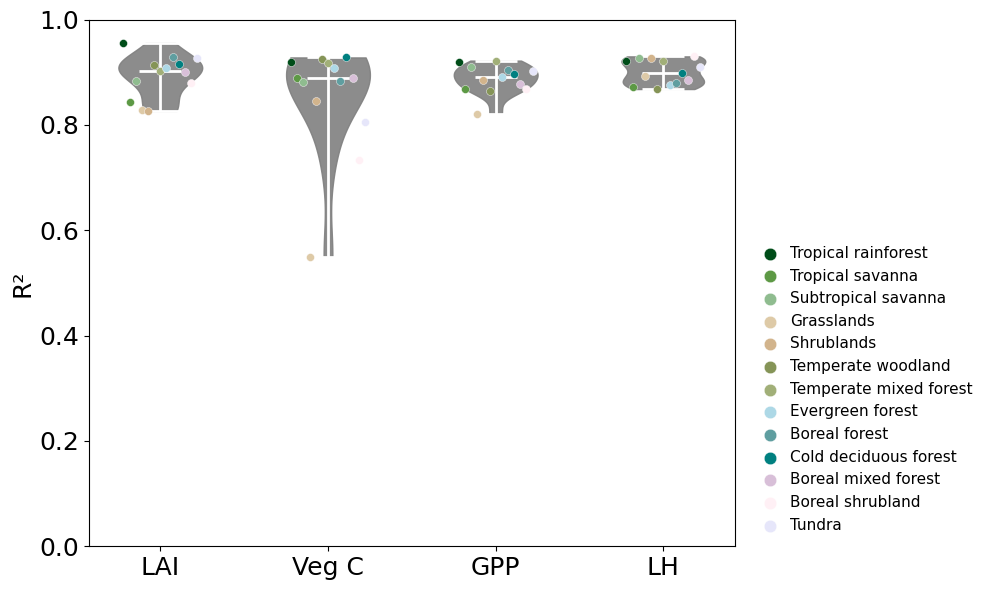

In [21]:
biome_names = [biome_info[str(num)]['name'] for num in range(1, 14)]

def plot_violin(ax, data, ylabel, title, show_ylim_one=True,
                biome_names=None, biome_colors=None):
    parts = ax.violinplot(data.T, showmeans=False, showmedians=True)

    for vp in parts['bodies']:
        vp.set_facecolor('grey')
        vp.set_edgecolor('grey')
        vp.set_alpha(0.9)

    for partname, element in parts.items():
        if partname == 'bodies':
            continue
        if hasattr(element, 'set_color'):
            element.set_color('white')
        if hasattr(element, 'set_linewidth'):
            element.set_linewidth(2)

    # scatter each biome on top of its violin
    if biome_names is not None:
        n_var, n_biome = data.shape
        # deterministic spread so points don't overlap
        offsets = np.linspace(-0.22, 0.22, n_biome)
        for j, (name, c) in enumerate(zip(biome_names, biome_colors)):
            ax.scatter(np.arange(1, n_var + 1) + offsets[j], data[:, j],
                       color=c, s=33, zorder=3, edgecolor='white',
                       linewidth=0.3, label=name)

    ax.set_ylabel(ylabel, fontsize=18)
    ax.tick_params(axis='y', labelsize=18)
    ax.set_title(title, fontsize=18)
    ax.set_xticks([1, 2, 3, 4])
    ax.set_xticklabels(['LAI', 'Veg C', 'GPP', 'LH'], fontsize=18)
    if show_ylim_one:
        ax.set_ylim([0, 1])


fig, axes = plt.subplots(1, 1, figsize=(10, 6))
plot_violin(axes, r2_eval, 'R²', '',
            biome_names = biome_names, biome_colors=biome_colors)
leg = axes.legend(loc='lower left', bbox_to_anchor=(1.01, 0), frameon=False,
                  fontsize=11, handletextpad=0.3)
for handle in leg.legend_handles:
    handle.set_sizes([80])
plt.tight_layout()
plt.savefig('../figs/SI_FigS13_emulator_eval_HMC.png', dpi=300, bbox_inches='tight')